# 11 · Hyper-parameter Tuning with Optuna

Bayesian optimisation (TPE) of the churn classifier and the GBM demand forecaster.

In [1]:
import sys, warnings, logging
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
logging.getLogger("cmdstanpy").setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)

from src.config import *
from src.ingestion.etl import load_processed
D = load_processed()
tx, customers, products, inventory = D["transactions"], D["customers"], D["products"], D["inventory"]
daily = D["daily"]
print(f"Loaded {len(tx):,} clean transaction lines | {tx.customer_id.nunique():,} customers | "
      f"{tx.order_date.min().date()} -> {tx.order_date.max().date()}")

Loaded 54,339 clean transaction lines | 1,455 customers | 2024-01-01 -> 2025-12-31


In [2]:
series = daily.set_index("date")["units"].astype(float)
train, test = series.iloc[:-HOLDOUT_DAYS], series.iloc[-HOLDOUT_DAYS:]

## 1. Tune the churn model (5-fold CV ROC-AUC)

In [3]:
import optuna
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
from src.churn.model import make_training_set
optuna.logging.set_verbosity(optuna.logging.WARNING)
X, y, _ = make_training_set(tx, customers)
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)

def churn_objective(trial):
    p = dict(n_estimators=trial.suggest_int("n_estimators", 80, 400),
             max_depth=trial.suggest_int("max_depth", 2, 5),
             learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
             subsample=trial.suggest_float("subsample", 0.6, 1.0),
             min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 20))
    return cross_val_score(GradientBoostingClassifier(random_state=SEED, **p), X, y, cv=cv, scoring="roc_auc", n_jobs=-1).mean()

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(churn_objective, n_trials=25)
print("best CV AUC:", round(study.best_value, 4)); print(study.best_params)

best CV AUC: 0.904
{'n_estimators': 320, 'max_depth': 2, 'learning_rate': 0.012034811849128937, 'subsample': 0.6157061052424886, 'min_samples_leaf': 13}


default params CV AUC 0.8922  ->  tuned 0.9040


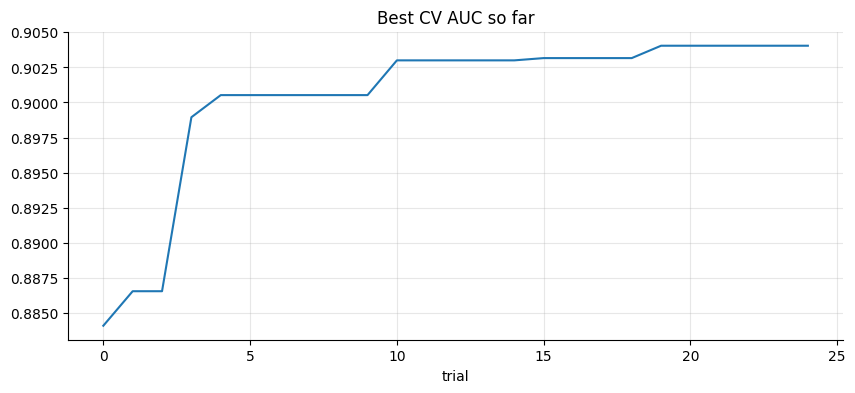

In [4]:
baseline = cross_val_score(GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=0.06, subsample=0.85, random_state=SEED), X, y, cv=cv, scoring="roc_auc").mean()
print(f"default params CV AUC {baseline:.4f}  ->  tuned {study.best_value:.4f}")
pd.Series({t.number: t.value for t in study.trials}).cummax().plot(title="Best CV AUC so far"); plt.xlabel("trial"); plt.show()

## 2. Tune the GBM forecaster (validation = last 60 days of the training window)
Tuning uses an inner validation split so the final holdout stays untouched.

In [5]:
from src.forecasting.gbm import GBMForecaster
from src.forecasting.ensemble import regression_metrics
inner_train, inner_val = train.iloc[:-60], train.iloc[-60:]

def fc_objective(trial):
    p = dict(max_iter=trial.suggest_int("max_iter", 100, 500),
             learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
             max_depth=trial.suggest_int("max_depth", 2, 7),
             min_samples_leaf=trial.suggest_int("min_samples_leaf", 5, 60),
             l2_regularization=trial.suggest_float("l2_regularization", 0.0, 5.0))
    fc = GBMForecaster(**p).fit(inner_train).forecast(60)
    return regression_metrics(inner_val.values, fc["yhat"].values)["mae"]

fstudy = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
fstudy.optimize(fc_objective, n_trials=20)
print("best inner-val MAE:", round(fstudy.best_value, 3)); print(fstudy.best_params)

best inner-val MAE: 11.274
{'max_iter': 414, 'learning_rate': 0.018187859051288217, 'max_depth': 5, 'min_samples_leaf': 38, 'l2_regularization': 0.23225206359998862}


## 3. Confirm on the untouched holdout

In [6]:
default = regression_metrics(test.values, GBMForecaster().fit(train).forecast(HOLDOUT_DAYS)["yhat"].values)
tuned = regression_metrics(test.values, GBMForecaster(**fstudy.best_params).fit(train).forecast(HOLDOUT_DAYS)["yhat"].values)
pd.DataFrame({"default": default, "tuned": tuned}).T.round(3)

,mae,rmse,wape,bias
default,15.649,19.848,0.122,4.213
tuned,14.810,18.227,0.116,5.008


**Takeaway:** tuned parameters are only adopted if they also help on the untouched holdout - otherwise we keep the simpler defaults used by the pipeline.